# Executive Summary

This report documents Task 2 of the Data Analyst Internship: a hands-on data lab covering environment setup, data manipulation, visualisation and exploratory analysis. The analysis is built on a synthetic but realistic Indian retail orders dataset covering 28 unique orders across 12 cities and 5 product categories, with all monetary values in INR (₹).

The workflow is fully reproducible: data generation uses a fixed seed (`np.random.default_rng(42)`), dependencies are pinned in `requirements.txt`, and the notebook ships with executed outputs. Key results: net revenue of **₹4,24,128.77**, total profit of **₹62,686.53** and an average profit margin of **14.8%**. Electronics leads revenue while Beauty leads margin, and discount percentage is strongly and negatively associated with profit margin (r = −0.87).

# 1. Data Science Environment Setup & Verification

An isolated virtual environment keeps project dependencies separate from the system Python installation, so the lab behaves identically on any machine. This section covers setup on both Windows and macOS/Linux, dependency freezing, JupyterLab launch, kernel selection and a programmatic verification script.

## 1.1 Create a Virtual Environment — Windows PowerShell

```bash
# --- Windows PowerShell ---
# 1. Open PowerShell in the project folder, then create the environment
python -m venv .venv

# 2. Allow script execution for this session (required on Windows)
Set-ExecutionPolicy -Scope Process -ExecutionPolicy RemoteSigned

# 3. Activate the environment
.\.venv\Scripts\Activate.ps1

# 4. Confirm the prompt now shows (.venv) and check Python
python --version

# 5. Upgrade pip
python -m pip install --upgrade pip
```

## 1.2 Create a Virtual Environment — macOS / Linux

```bash
# --- macOS / Linux terminal ---
# 1. Create the environment
python3 -m venv .venv

# 2. Activate it
source .venv/bin/activate

# 3. Confirm the prompt now shows (.venv) and check Python
python --version

# 4. Upgrade pip
python -m pip install --upgrade pip
```

## 1.3 Install the Required Libraries

With the environment activated, install the full data-science stack in one command.

```python
# Install the core data-science stack into the ACTIVE environment
pip install pandas numpy matplotlib seaborn scipy jupyterlab

# Verify a library imports correctly
python -c "import pandas as pd, numpy as np; print(pd.__version__, np.__version__)"
```

## 1.4 Freeze Dependencies into requirements.txt

`pip freeze` writes the exact versions currently installed. Pinning these versions is what makes the project reproducible for an evaluator.

```bash
# Freeze the exact versions currently installed into requirements.txt
pip freeze > requirements.txt

# Show the file contents
cat requirements.txt          # macOS / Linux
# Get-Content requirements.txt   # Windows PowerShell
```

The versions used for this project:

```bash
pandas==2.2.3
numpy==2.3.5
matplotlib==3.11.2
seaborn==0.13.2
scipy==1.17.1
jupyterlab>=4.0
```

## 1.5 Launch JupyterLab and Select the Kernel

JupyterLab is the interactive development environment used for this lab. Selecting the correct kernel ensures the notebook runs on the virtual environment's Python, not the system Python.

```bash
# Launch JupyterLab from the project root (environment must be active)
jupyter lab

# Then, in the browser window that opens:
#   1. Use File > Open to load Hands_On_Data_Lab.ipynb
#   2. If the kernel is not selected, use
#        Kernel > Change kernel > Python 3 (ipykernel)
#   3. Run the whole notebook top to bottom with Run > Run All Cells
```

## 1.6 Create the Project Folder Structure

The project uses a fixed layout so that every file reference is stable. The cell below creates `data/` and `outputs/` and prints the tree.

In [1]:
import os

for folder in ["data", "outputs"]:
    os.makedirs(folder, exist_ok=True)
    print(f"created / verified: {folder}/")

print("\nProject structure:")
for root, dirs, files in os.walk("."):
    dirs[:] = sorted(d for d in dirs
                     if d not in ("__pycache__", ".git", ".venv", "ipynb_checkpoints"))
    depth = root.count(os.sep)
    label = os.path.basename(root) or "."
    print("  " * depth + f"{label}/")
    for name in sorted(files):
        print("  " * (depth + 1) + name)

created / verified: data/
created / verified: outputs/

Project structure:
./
  Hands_On_Data_Lab.ipynb
  Hands_On_Data_Lab_Report.docx
  README.md
  build_all.py
  content.py
  requirements.txt
  verify_environment.py
  data/
    cleaned_retail_orders.csv
    raw_retail_orders.csv
  outputs/
    01_category_revenue_profit.png
    02_monthly_trend.png
    03_segment_order_value.png
    04_discount_margin.png
    category_summary.csv
    monthly_summary.csv


## 1.7 Environment Verification Script

The script below checks the Python version, every required library, the working directory, the expected folders and key files, and a seeded reproducibility draw. It prints a clear PASS/FAIL line for each check and raises an `AssertionError` if anything important is missing. The identical script is saved as `verify_environment.py`.

In [2]:
"""verify_environment.py -- Task 2 environment verification.

Run from the project root with the virtual environment active:

    python verify_environment.py

Prints a clear PASS/FAIL line for every check and raises AssertionError
if any required check fails, so it can also be used in automated setup.
"""

import importlib.metadata as metadata
import sys
from pathlib import Path

import matplotlib
import numpy as np
import pandas as pd
import scipy
import seaborn

PROJECT_ROOT = Path.cwd()
EXPECTED_FOLDERS = ["data", "outputs"]
EXPECTED_FILES = ["Hands_On_Data_Lab.ipynb", "README.md", "requirements.txt"]
REQUIRED_LIBRARIES = {
    "numpy": np,
    "pandas": pd,
    "matplotlib": matplotlib,
    "seaborn": seaborn,
    "scipy": scipy,
}

results = []


def check(name, condition, detail=""):
    """Print a PASS/FAIL line and record the result."""
    status = "PASS" if condition else "FAIL"
    line = f"[{status}] {name}"
    if detail:
        line += f" -- {detail}"
    print(line)
    results.append((name, bool(condition), detail))


print("=" * 70)
print("HANDS-ON DATA LAB -- ENVIRONMENT VERIFICATION")
print("=" * 70)

print(f"\nPython version    : {sys.version.split()[0]}")
print(f"Working directory : {PROJECT_ROOT}")

print("\n--- Required libraries ---")
for name, module in REQUIRED_LIBRARIES.items():
    print(f"{name:<13} {module.__version__}")
try:
    jupyterlab_version = metadata.version("jupyterlab")
except metadata.PackageNotFoundError:
    jupyterlab_version = None
print(f"{'jupyterlab':<13} {jupyterlab_version or 'NOT INSTALLED'}")

print("\n--- Project folders ---")
for folder in EXPECTED_FOLDERS:
    check(f"folder '{folder}/' exists", (PROJECT_ROOT / folder).is_dir())

print("\n--- Key project files ---")
for name in EXPECTED_FILES:
    check(f"file '{name}' exists", (PROJECT_ROOT / name).is_file())

print("\n--- Version sanity ---")
check("pandas is version 2.x", pd.__version__.startswith("2."), pd.__version__)
check("numpy is installed", numpy_ok := np.__version__ is not None, np.__version__)
check("jupyterlab is installed", jupyterlab_version is not None,
      jupyterlab_version or "missing")

print("\n--- Reproducibility check: np.random.default_rng(42) ---")
draw_one = np.random.default_rng(42).integers(0, 1000, size=5)
draw_two = np.random.default_rng(42).integers(0, 1000, size=5)
print("Draw 1:", draw_one)
print("Draw 2:", draw_two)
check("seeded draws are identical", np.array_equal(draw_one, draw_two))

print("\n" + "=" * 70)
failed = [name for name, ok, _ in results if not ok]
if failed:
    print(f"RESULT: FAIL -- {len(failed)} check(s) failed: {', '.join(failed)}")
    raise AssertionError(f"Environment verification failed: {failed}")
print(f"RESULT: PASS -- all {len(results)} checks succeeded.")
print("=" * 70)

HANDS-ON DATA LAB -- ENVIRONMENT VERIFICATION

Python version    : 3.13.18
Working directory : /home/user/Hands_On_Data_Lab

--- Required libraries ---
numpy         2.3.5
pandas        2.2.3
matplotlib    3.11.2
seaborn       0.13.2
scipy         1.17.1
jupyterlab    4.6.6

--- Project folders ---
[PASS] folder 'data/' exists
[PASS] folder 'outputs/' exists

--- Key project files ---
[PASS] file 'Hands_On_Data_Lab.ipynb' exists
[PASS] file 'README.md' exists
[PASS] file 'requirements.txt' exists

--- Version sanity ---
[PASS] pandas is version 2.x -- 2.2.3
[PASS] numpy is installed -- 2.3.5
[PASS] jupyterlab is installed -- 4.6.6

--- Reproducibility check: np.random.default_rng(42) ---
Draw 1: [ 89 773 654 438 433]
Draw 2: [ 89 773 654 438 433]
[PASS] seeded draws are identical

RESULT: PASS -- all 9 checks succeeded.


**Reading the output:** every line should read PASS. The two seeded draws must be identical — that is the reproducibility guarantee the whole lab depends on.

# 2. Practical Data Manipulation Exercises (Pandas & NumPy)

## 2.1 Build the Raw Dataset

The generator below is reproducible from `SEED = 42`. It creates 28 orders and then deliberately injects five realistic imperfections: inconsistent casing, stray spaces, missing values, unusual values and duplicate rows. The result is saved as `data/raw_retail_orders.csv`.

In [3]:
import numpy as np
import pandas as pd

SEED = 42
rng = np.random.default_rng(SEED)

cities = ["Mumbai", "Delhi", "Bengaluru", "Jaipur", "Lucknow", "Indore",
          "Pune", "Ahmedabad", "Chennai", "Kolkata", "Hyderabad", "Chandigarh"]
region_map = {
    "Mumbai": "West", "Pune": "West", "Ahmedabad": "West", "Indore": "West",
    "Delhi": "North", "Jaipur": "North", "Lucknow": "North", "Chandigarh": "North",
    "Bengaluru": "South", "Chennai": "South", "Hyderabad": "South",
    "Kolkata": "East",
}
categories = ["Electronics", "Fashion", "Grocery", "Home & Kitchen", "Beauty"]
products = {
    "Electronics": ["Samsung 55-inch 4K Smart TV", "boAt Airdopes 141 Earbuds",
                    "Mi 20000mAh Power Bank", "Sony WH-1000XM4 Headphones",
                    "Apple iPad 10th Gen"],
    "Fashion": ["Allen Solley Formal Shirt", "Levi's 511 Jeans",
                "Nike Revolution 6 Running Shoes", "Biba Cotton Kurta",
                "Van Heusen Premium Blazer"],
    "Grocery": ["Aashirvaad Whole Wheat Atta 5kg", "Fortune Sunflower Oil 1L",
                "Tata Salt 1kg", "Amul Butter 500g", "India Gate Basmati Rice 5kg"],
    "Home & Kitchen": ["Prestige Induction Cooktop", "Borosil Glass Bowl Set",
                       "Milton Thermosteel Flask 1L", "Nayasa Plastic Storage Box Set",
                       "Pigeon Non-Stick Pan"],
    "Beauty": ["Lakme Absolute Foundation", "Himalaya Neem Face Wash",
               "Maybelline Colossal Kajal", "Dove Body Lotion 400ml",
               "Nykaa Vitamin C Serum"],
}
segments = ["New", "Returning", "Premium"]
payments = ["UPI", "Credit Card", "Debit Card", "Cash on Delivery", "Net Banking"]
cost_rate = {"Electronics": 0.72, "Fashion": 0.62, "Grocery": 0.80,
             "Home & Kitchen": 0.70, "Beauty": 0.55}

n = 28
# Balanced city coverage: every city appears two or three times
city_pool = (cities * 3)[:n]
rng.shuffle(city_pool)
city = np.array(city_pool)

category = rng.choice(categories, size=n)
product_name = np.array([rng.choice(products[c]) for c in category])
units = rng.integers(1, 12, size=n)
unit_price = np.round(rng.uniform(150, 4500, size=n), 2)
unit_cost = np.round(
    unit_price * np.array([cost_rate[c] for c in category]) * rng.uniform(0.95, 1.05, size=n),
    2,
)
discount = np.round(rng.uniform(0, 30, size=n), 1)
segment = rng.choice(segments, size=n, p=[0.4, 0.4, 0.2])
payment = rng.choice(payments, size=n)
customer_id = np.array([f"CUST-{rng.integers(100, 300)}" for _ in range(n)])

# Stratified dates: four or five orders per month, January-June 2025
dates = []
for month, quota in enumerate([5, 5, 5, 5, 4, 4], start=1):
    days_in_month = pd.Period(f"2025-{month:02d}").days_in_month
    for day in rng.choice(days_in_month, size=quota, replace=False) + 1:
        dates.append(pd.Timestamp(2025, month, int(day)))
dates = pd.Series(dates).sort_values().reset_index(drop=True)

# Store dates as mixed-format strings, exactly as a raw export would
date_str = [
    d.strftime("%d-%m-%Y") if i % 3 == 0
    else (d.strftime("%Y/%m/%d") if i % 3 == 1 else d.strftime("%d %b %Y"))
    for i, d in enumerate(dates)
]

raw_orders = pd.DataFrame({
    "order_id": [f"ORD-{1000 + i}" for i in range(1, n + 1)],
    "order_date": date_str,
    "customer_id": customer_id,
    "city": city,
    "region": [region_map[c] for c in city],
    "product_category": category,
    "product_name": product_name,
    "units_sold": units,
    "unit_price": unit_price,
    "unit_cost": unit_cost,
    "discount_percentage": discount,
    "customer_segment": segment,
    "payment_mode": payment,
})

# --- Inject realistic imperfections, deterministically ---
# 1. Inconsistent text casing
raw_orders.loc[2, "city"] = raw_orders.loc[2, "city"].upper()      # "MUMBAI"
raw_orders.loc[7, "city"] = raw_orders.loc[7, "city"].lower()      # "delhi"
raw_orders.loc[15, "city"] = raw_orders.loc[15, "city"].upper()
raw_orders.loc[3, "payment_mode"] = "upi"
raw_orders.loc[9, "payment_mode"] = "CREDIT CARD"
raw_orders.loc[12, "product_category"] = "electronics"
raw_orders.loc[20, "customer_segment"] = "premium"
# 2. Leading and trailing spaces
raw_orders.loc[4, "city"] = " " + raw_orders.loc[4, "city"] + "  "
raw_orders.loc[6, "product_category"] = " " + raw_orders.loc[6, "product_category"] + " "
raw_orders.loc[10, "payment_mode"] = " " + raw_orders.loc[10, "payment_mode"] + " "
# 3. Missing values
raw_orders.loc[[5, 19, 23, 27], "discount_percentage"] = np.nan
raw_orders.loc[[2, 16], "customer_segment"] = np.nan
raw_orders.loc[[8, 21], "payment_mode"] = np.nan
raw_orders.loc[11, "city"] = np.nan
raw_orders.loc[14, "product_name"] = np.nan
# 4. Unusual values that require investigation (price and cost kept consistent)
raw_orders.loc[3, "discount_percentage"] = 70.0                 # deep clearance discount
raw_orders.loc[9, "units_sold"] = 60                            # bulk / B2B-style order
raw_orders.loc[17, "product_category"] = "Electronics"          # premium high-ticket order
raw_orders.loc[17, "product_name"] = "Samsung 55-inch 4K Smart TV"
raw_orders.loc[17, "unit_price"] = 12999.0
raw_orders.loc[17, "unit_cost"] = round(12999.0 * cost_rate["Electronics"], 2)
raw_orders.loc[17, "units_sold"] = 6
# 5. Duplicate records
raw_orders = pd.concat([raw_orders, raw_orders.iloc[[5, 19]]], ignore_index=True)

raw_orders.to_csv("data/raw_retail_orders.csv", index=False)

print(f"Rows: {len(raw_orders)} | duplicate rows: {raw_orders.duplicated().sum()} | "
      f"missing values: {raw_orders.isna().sum().sum()}")
raw_orders.head(8)

Rows: 30 | duplicate rows: 2 | missing values: 12


,order_id,order_date,customer_id,city,region,product_category,product_name,units_sold,unit_price,unit_cost,discount_percentage,customer_segment,payment_mode
0,ORD-1001,02-01-2025,CUST-104,Ahmedabad,West,Electronics,Apple iPad 10th Gen,9,758.12,557.98,5.3,Premium,Cash on Delivery
1,ORD-1002,2025/01/06,CUST-254,Lucknow,North,Grocery,Amul Butter 500g,10,648.21,516.59,25.7,Returning,Credit Card
2,ORD-1003,09 Jan 2025,CUST-167,CHANDIGARH,North,Beauty,Himalaya Neem Face Wash,5,3057.55,1624.69,22.8,NaN,Cash on Delivery
3,ORD-1004,10-01-2025,CUST-232,Hyderabad,South,Electronics,Apple iPad 10th Gen,9,2199.27,1583.64,70.0,New,upi
4,ORD-1005,2025/01/31,CUST-182,Indore,West,Beauty,Maybelline Colossal Kajal,10,2608.78,1384.94,13.0,New,Net Banking
5,ORD-1006,01 Feb 2025,CUST-174,Indore,West,Beauty,Himalaya Neem Face Wash,5,3477.75,1950.31,NaN,Returning,Credit Card
6,ORD-1007,04-02-2025,CUST-277,Jaipur,North,Fashion,Van Heusen Premium Blazer,10,2911.02,1795.11,17.5,Returning,Net Banking
7,ORD-1008,2025/02/11,CUST-118,mumbai,West,Home & Kitchen,Borosil Glass Bowl Set,4,2558.07,1769.34,19.5,New,Net Banking


**Analytical note:** the raw file has 30 rows, 2 duplicates and 12 missing values. Dates appear in three formats (`DD-MM-YYYY`, `YYYY/MM/DD`, `DD Mon YYYY`), exactly as a raw order-system export would produce.

## 2.2 Exercise 1 — Data Inspection

Inspection establishes what the data actually contains before any transformation. Each method answers a different question: `.shape` the size, `.info()` the structure, `.describe()` the numeric spread, `.dtypes` the storage types, `.isna().sum()` the gaps and `.duplicated().sum()` the repetition.

In [4]:
# Exercise 1 -- data inspection
raw = pd.read_csv("data/raw_retail_orders.csv")

print("=== First 5 rows: .head() ===")
display(raw.head())

print("=== Last 3 rows: .tail(3) ===")
display(raw.tail(3))

print("=== Shape: .shape ===")
print(raw.shape)

print("\n=== Structure: .info() ===")
raw.info()

print("\n=== Numeric summary: .describe() ===")
display(raw.describe().round(2))

print("\n=== Column types: .dtypes ===")
print(raw.dtypes.to_string())

print("\n=== Missing values per column: .isna().sum() ===")
print(raw.isna().sum().to_string())

print("\n=== Duplicate rows: .duplicated().sum() ===")
print(raw.duplicated().sum())

=== First 5 rows: .head() ===


,order_id,order_date,customer_id,city,region,product_category,product_name,units_sold,unit_price,unit_cost,discount_percentage,customer_segment,payment_mode
0,ORD-1001,02-01-2025,CUST-104,Ahmedabad,West,Electronics,Apple iPad 10th Gen,9,758.12,557.98,5.3,Premium,Cash on Delivery
1,ORD-1002,2025/01/06,CUST-254,Lucknow,North,Grocery,Amul Butter 500g,10,648.21,516.59,25.7,Returning,Credit Card
2,ORD-1003,09 Jan 2025,CUST-167,CHANDIGARH,North,Beauty,Himalaya Neem Face Wash,5,3057.55,1624.69,22.8,NaN,Cash on Delivery
3,ORD-1004,10-01-2025,CUST-232,Hyderabad,South,Electronics,Apple iPad 10th Gen,9,2199.27,1583.64,70.0,New,upi
4,ORD-1005,2025/01/31,CUST-182,Indore,West,Beauty,Maybelline Colossal Kajal,10,2608.78,1384.94,13.0,New,Net Banking


=== Last 3 rows: .tail(3) ===


,order_id,order_date,customer_id,city,region,product_category,product_name,units_sold,unit_price,unit_cost,discount_percentage,customer_segment,payment_mode
27,ORD-1028,28-06-2025,CUST-274,Chennai,South,Home & Kitchen,Borosil Glass Bowl Set,7,541.71,382.20,NaN,Premium,Credit Card
28,ORD-1006,01 Feb 2025,CUST-174,Indore,West,Beauty,Himalaya Neem Face Wash,5,3477.75,1950.31,NaN,Returning,Credit Card
29,ORD-1020,2025/04/26,CUST-266,Chandigarh,North,Electronics,Sony WH-1000XM4 Headphones,8,3029.34,2228.43,NaN,Premium,Cash on Delivery


=== Shape: .shape ===
(30, 13)

=== Structure: .info() ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   order_id             30 non-null     object 
 1   order_date           30 non-null     object 
 2   customer_id          30 non-null     object 
 3   city                 29 non-null     object 
 4   region               30 non-null     object 
 5   product_category     30 non-null     object 
 6   product_name         29 non-null     object 
 7   units_sold           30 non-null     int64  
 8   unit_price           30 non-null     float64
 9   unit_cost            30 non-null     float64
 10  discount_percentage  24 non-null     float64
 11  customer_segment     28 non-null     object 
 12  payment_mode         28 non-null     object 
dtypes: float64(3), int64(1), object(9)
memory usage: 3.2+ KB

=== Numeric summary: .des

,units_sold,unit_price,unit_cost,discount_percentage
count,30.00,30.00,30.00,24.00
mean,8.53,2448.75,1683.61,15.74
std,10.05,2289.98,1668.07,14.52
min,1.00,248.80,170.78,0.70
25%,5.00,1104.49,678.84,4.90
50%,7.50,2378.67,1510.02,14.70
75%,9.00,3037.16,1950.31,20.32
max,60.00,12999.00,9359.28,70.00



=== Column types: .dtypes ===
order_id                object
order_date              object
customer_id             object
city                    object
region                  object
product_category        object
product_name            object
units_sold               int64
unit_price             float64
unit_cost              float64
discount_percentage    float64
customer_segment        object
payment_mode            object

=== Missing values per column: .isna().sum() ===
order_id               0
order_date             0
customer_id            0
city                   1
region                 0
product_category       0
product_name           1
units_sold             0
unit_price             0
unit_cost              0
discount_percentage    6
customer_segment       2
payment_mode           2

=== Duplicate rows: .duplicated().sum() ===
2


**Observations:** 30 rows and 13 columns; `order_date` is stored as text (`object`), not datetime; `discount_percentage`, `customer_segment`, `payment_mode`, `city` and `product_name` contain missing values; and 2 rows are exact duplicates.

## 2.3 Exercise 2 — Data Cleaning

The cleaning order matters: remove duplicates first so that imputation statistics are not biased by repeated rows, then standardise text, parse dates, and impute. Median is used for numeric columns (robust to outliers) and mode for categorical ones.

In [5]:
# Exercise 2 -- data cleaning
orders = raw.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {len(raw) - len(orders)} rows")

# Standardise categorical text
for column in ["city", "product_category", "payment_mode", "customer_segment"]:
    orders[column] = orders[column].str.strip().str.title()
# .str.title() lowercases acronyms ("UPI" -> "Upi"); restore known ones
orders["payment_mode"] = orders["payment_mode"].replace({"Upi": "UPI"})

# Parse mixed-format dates (day-first because Indian formats lead with the day)
orders["order_date"] = pd.to_datetime(orders["order_date"], format="mixed", dayfirst=True)

# Impute missing values: median for numeric, mode for categorical
orders["discount_percentage"] = orders["discount_percentage"].fillna(
    orders["discount_percentage"].median())
orders["customer_segment"] = orders["customer_segment"].fillna(
    orders["customer_segment"].mode()[0])
orders["payment_mode"] = orders["payment_mode"].fillna(orders["payment_mode"].mode()[0])
orders["city"] = orders["city"].fillna(orders["city"].mode()[0])
orders["product_name"] = orders["product_name"].fillna("Unknown Product")

# Region must follow the cleaned city values
orders["region"] = orders["city"].map(region_map)

orders.to_csv("data/cleaned_retail_orders.csv", index=False)

print(f"Rows after cleaning: {len(orders)} | missing values: {orders.isna().sum().sum()}")
print(f"Date range: {orders['order_date'].min().date()} to {orders['order_date'].max().date()}")
orders.head(8)

Duplicates removed: 2 rows
Rows after cleaning: 28 | missing values: 0
Date range: 2025-01-02 to 2025-06-28


,order_id,order_date,customer_id,city,region,product_category,product_name,units_sold,unit_price,unit_cost,discount_percentage,customer_segment,payment_mode
0,ORD-1001,2025-01-02,CUST-104,Ahmedabad,West,Electronics,Apple iPad 10th Gen,9,758.12,557.98,5.3,Premium,Cash On Delivery
1,ORD-1002,2025-01-06,CUST-254,Lucknow,North,Grocery,Amul Butter 500g,10,648.21,516.59,25.7,Returning,Credit Card
2,ORD-1003,2025-01-09,CUST-167,Chandigarh,North,Beauty,Himalaya Neem Face Wash,5,3057.55,1624.69,22.8,New,Cash On Delivery
3,ORD-1004,2025-01-10,CUST-232,Hyderabad,South,Electronics,Apple iPad 10th Gen,9,2199.27,1583.64,70.0,New,UPI
4,ORD-1005,2025-01-31,CUST-182,Indore,West,Beauty,Maybelline Colossal Kajal,10,2608.78,1384.94,13.0,New,Net Banking
5,ORD-1006,2025-02-01,CUST-174,Indore,West,Beauty,Himalaya Neem Face Wash,5,3477.75,1950.31,14.7,Returning,Credit Card
6,ORD-1007,2025-02-04,CUST-277,Jaipur,North,Fashion,Van Heusen Premium Blazer,10,2911.02,1795.11,17.5,Returning,Net Banking
7,ORD-1008,2025-02-11,CUST-118,Mumbai,West,Home & Kitchen,Borosil Glass Bowl Set,4,2558.07,1769.34,19.5,New,Net Banking


| Cleaning step | Technique | Why this choice |
| --- | --- | --- |
| Duplicates | `.drop_duplicates()` | Exact repeats inflate counts and bias every aggregate. |
| Text casing | `.str.strip().str.title()` | Removes stray spaces and unifies case; acronyms restored with `.replace()`. |
| Dates | `pd.to_datetime(format="mixed", dayfirst=True)` | Handles all three formats at once and stores real datetimes. |
| Missing discounts | Median imputation | Robust to the 70% clearance outlier. |
| Missing segment / payment | Mode imputation | Categorical columns use the most frequent value. |
| Missing city | Mode imputation | Restores a valid value so the region mapping works. |
| Missing product name | Fill with "Unknown Product" | Keeps the row without inventing a product. |

**Result:** 28 clean rows, zero missing values, dates parsed from 2 January 2025 to 28 June 2025. The raw file is preserved unchanged at `data/raw_retail_orders.csv`; the cleaned file is saved to `data/cleaned_retail_orders.csv`.

## 2.4 Exercise 3 — Calculated Business Metrics

Raw columns are converted into business meaning. Gross revenue ignores the discount, net revenue applies it, and profit subtracts the cost of goods. NumPy's `np.where` and pandas' `pd.cut`-style thresholds classify each order.

In [6]:
# Exercise 3 -- calculated business metrics
orders["gross_revenue"] = (orders["units_sold"] * orders["unit_price"]).round(2)
orders["discount_amount"] = (orders["gross_revenue"] * orders["discount_percentage"] / 100).round(2)
orders["net_revenue"] = (orders["gross_revenue"] - orders["discount_amount"]).round(2)
orders["total_cost"] = (orders["units_sold"] * orders["unit_cost"]).round(2)
orders["profit"] = (orders["net_revenue"] - orders["total_cost"]).round(2)
orders["profit_margin_pct"] = (orders["profit"] / orders["net_revenue"] * 100).round(1)

# Time dimensions
orders["order_month"] = orders["order_date"].dt.to_period("M").astype(str)
orders["order_quarter"] = "Q" + orders["order_date"].dt.quarter.astype(str)

# Order value classification
orders["order_value_class"] = np.where(
    orders["net_revenue"] >= 25_000, "High Value",
    np.where(orders["net_revenue"] >= 10_000, "Medium Value", "Low Value"),
)

print(orders[["order_id", "gross_revenue", "discount_amount", "net_revenue",
              "total_cost", "profit", "profit_margin_pct"]].head(8).to_string(index=False))
print("\nOrder value classes:")
print(orders["order_value_class"].value_counts().to_string())
print("\nOrder quarters:")
print(orders["order_quarter"].value_counts().to_string())

# Re-save the cleaned file so it also carries the derived business metrics
orders.to_csv("data/cleaned_retail_orders.csv", index=False)
print("\nSaved the enriched, analysis-ready dataset to "
      "data/cleaned_retail_orders.csv")

order_id  gross_revenue  discount_amount  net_revenue  total_cost   profit  profit_margin_pct
ORD-1001        6823.08           361.62      6461.46     5021.82  1439.64               22.3
ORD-1002        6482.10          1665.90      4816.20     5165.90  -349.70               -7.3
ORD-1003       15287.75          3485.61     11802.14     8123.45  3678.69               31.2
ORD-1004       19793.43         13855.40      5938.03    14252.76 -8314.73             -140.0
ORD-1005       26087.80          3391.41     22696.39    13849.40  8846.99               39.0
ORD-1006       17388.75          2556.15     14832.60     9751.55  5081.05               34.3
ORD-1007       29110.20          5094.28     24015.92    17951.10  6064.82               25.3
ORD-1008       10232.28          1995.29      8236.99     7077.36  1159.63               14.1

Order value classes:
order_value_class
Low Value       15
Medium Value     9
High Value       4

Order quarters:
order_quarter
Q1    15
Q2    13

Saved t

## 2.5 Exercise 3 (continued) — Filtering, Slicing and Sorting

In [7]:
# Exercise 3 (continued) -- filtering, slicing and sorting
print("=== Boolean filtering: multiple conditions ===")
discounted_electronics = orders[(orders["product_category"] == "Electronics")
                                & (orders["discount_percentage"] > 15)]
print(f"Electronics orders with discount above 15%: {len(discounted_electronics)}")
print(discounted_electronics[["order_id", "city", "discount_percentage",
                              "profit_margin_pct"]].to_string(index=False))

print("\n=== .loc[] -- label-based row and column selection ===")
print(orders.loc[orders["region"] == "West",
                 ["order_id", "city", "net_revenue"]].to_string(index=False))

print("\n=== .iloc[] -- positional slice (first 3 rows, first 4 columns) ===")
print(orders.iloc[:3, :4].to_string(index=False))

print("\n=== .sort_values() -- top 5 orders by net revenue ===")
print(orders.sort_values("net_revenue", ascending=False)
      .head(5)[["order_id", "city", "product_category", "net_revenue"]].to_string(index=False))

=== Boolean filtering: multiple conditions ===
Electronics orders with discount above 15%: 2
order_id      city  discount_percentage  profit_margin_pct
ORD-1004 Hyderabad                 70.0             -140.0
ORD-1018   Kolkata                 27.8                0.3

=== .loc[] -- label-based row and column selection ===
order_id      city  net_revenue
ORD-1001 Ahmedabad      6461.46
ORD-1005    Indore     22696.39
ORD-1006    Indore     14832.60
ORD-1008    Mumbai      8236.99
ORD-1010      Pune     77289.45
ORD-1011 Ahmedabad      2245.21
ORD-1013      Pune      9761.79
ORD-1016    Mumbai       962.14
ORD-1019    Mumbai     10609.28

=== .iloc[] -- positional slice (first 3 rows, first 4 columns) ===
order_id order_date customer_id       city
ORD-1001 2025-01-02    CUST-104  Ahmedabad
ORD-1002 2025-01-06    CUST-254    Lucknow
ORD-1003 2025-01-09    CUST-167 Chandigarh

=== .sort_values() -- top 5 orders by net revenue ===
order_id      city product_category  net_revenue
ORD-1010 

**Analytical note:** `.loc` selects by label and `.iloc` by position. Bracketing each boolean condition keeps multi-condition filters readable and correct. After the metrics are added, `data/cleaned_retail_orders.csv` is re-saved as the enriched, analysis-ready dataset (28 rows, 22 columns), while the original raw export remains untouched.

## 2.6 Exercise 3 (continued) — Investigating Unusual Values

Three orders were deliberately made unusual. They are genuine transactions, so they are retained — but they are flagged for review rather than silently included in averages.

In [8]:
# Investigate the unusual values injected earlier
unusual = orders[(orders["discount_percentage"] > 60)
                 | (orders["units_sold"] > 50)
                 | (orders["unit_price"] > 10_000)]
print("Orders flagged for investigation:")
print(unusual[["order_id", "city", "product_category", "units_sold", "unit_price",
               "discount_percentage", "net_revenue", "profit"]].to_string(index=False))

print("\nInterpretation:")
print("- ORD-1004: 70% clearance discount on an Electronics order produced a loss.")
print("- ORD-1010: a 60-unit bulk order; legitimate B2B-style demand, but it concentrates revenue.")
print("- ORD-1018: a premium Rs.12,999 television; high revenue, near-zero margin after discount.")
print("\nDecision: all three are retained (they are genuine transactions), but they are")
print("flagged so that pricing approvals and bulk-order terms can be reviewed.")

Orders flagged for investigation:
order_id      city product_category  units_sold  unit_price  discount_percentage  net_revenue   profit
ORD-1004 Hyderabad      Electronics           9     2199.27                 70.0      5938.03 -8314.73
ORD-1010      Pune   Home & Kitchen          60     1472.18                 12.5     77289.45 14652.45
ORD-1018   Kolkata      Electronics           6    12999.00                 27.8     56311.67   155.99

Interpretation:
- ORD-1004: 70% clearance discount on an Electronics order produced a loss.
- ORD-1010: a 60-unit bulk order; legitimate B2B-style demand, but it concentrates revenue.
- ORD-1018: a premium Rs.12,999 television; high revenue, near-zero margin after discount.

Decision: all three are retained (they are genuine transactions), but they are
flagged so that pricing approvals and bulk-order terms can be reviewed.


## 2.7 Exercise 4 — Grouping, Aggregation and Reshaping

Aggregations answer the questions managers ask. Two summary files are produced exactly as specified, and a regional-target lookup is merged in to measure achievement.

In [9]:
# Exercise 4 -- grouping, aggregation and reshaping
category_summary = (
    orders.groupby("product_category")
    .agg(
        total_orders=("order_id", "count"),
        total_units_sold=("units_sold", "sum"),
        gross_revenue_inr=("gross_revenue", "sum"),
        net_revenue_inr=("net_revenue", "sum"),
        total_profit_inr=("profit", "sum"),
        avg_order_value_inr=("net_revenue", "mean"),
        profit_margin_pct=("profit", "sum"),
    )
    .round(2)
)
# Margin is weighted: total profit divided by total revenue
category_summary["profit_margin_pct"] = (
    category_summary["total_profit_inr"] / category_summary["net_revenue_inr"] * 100
).round(1)
category_summary = category_summary.sort_values("net_revenue_inr", ascending=False)
category_summary.to_csv("outputs/category_summary.csv")
print("=== Category summary ===")
print(category_summary.to_string())

monthly_summary = (
    orders.groupby("order_month")
    .agg(
        total_orders=("order_id", "count"),
        total_units_sold=("units_sold", "sum"),
        gross_revenue_inr=("gross_revenue", "sum"),
        net_revenue_inr=("net_revenue", "sum"),
        total_profit_inr=("profit", "sum"),
        avg_order_value_inr=("net_revenue", "mean"),
    )
    .round(2)
)
monthly_summary["profit_margin_pct"] = (
    monthly_summary["total_profit_inr"] / monthly_summary["net_revenue_inr"] * 100
).round(1)
monthly_summary.to_csv("outputs/monthly_summary.csv")
print("\n=== Monthly summary ===")
print(monthly_summary.to_string())

print("\n=== Pivot table: net revenue by category x segment ===")
pivot = orders.pivot_table(index="product_category", columns="customer_segment",
                           values="net_revenue", aggfunc="sum", fill_value=0).round(0)
print(pivot.to_string())

print("\n=== Regional performance vs H1 target (merge) ===")
regional_targets = pd.DataFrame({
    "region": ["North", "South", "East", "West"],
    "h1_target_inr": [160_000, 120_000, 80_000, 170_000],
})
regional = (
    orders.groupby("region")
    .agg(total_orders=("order_id", "count"),
         net_revenue_inr=("net_revenue", "sum"),
         total_profit_inr=("profit", "sum"))
    .round(2)
    .reset_index()
    .merge(regional_targets, on="region", how="left")
)
regional["achievement_pct"] = (regional["net_revenue_inr"]
                               / regional["h1_target_inr"] * 100).round(1)
print(regional.to_string(index=False))

=== Category summary ===
                  total_orders  total_units_sold  gross_revenue_inr  net_revenue_inr  total_profit_inr  avg_order_value_inr  profit_margin_pct
product_category                                                                                                                              
Electronics                  8                60          169945.28        126548.46           3719.78             15818.56                2.9
Home & Kitchen               7               103          122597.08        106337.65          19629.65             15191.09               18.5
Grocery                      5                38          107718.45         95202.13           8913.96             19040.43                9.4
Beauty                       5                24           65713.24         55825.97          20119.96             11165.19               36.0
Fashion                      3                18           48648.18         40214.56          10303.18             13

region  total_orders  net_revenue_inr  total_profit_inr  h1_target_inr  achievement_pct
  East             1         56311.67            155.99          80000             70.4
 North            10        139326.35          20627.08         160000             87.1
 South             8         75395.44           6113.39         120000             62.8
  West             9        153095.31          35790.07         170000             90.1


**Analytical note:** profit margin is computed as total profit divided by total revenue (weighted), not as an average of per-order margins, so large orders are weighted correctly. The two required summary files are saved to `outputs/category_summary.csv` and `outputs/monthly_summary.csv`.

# 3. Practical Data Visualization (Matplotlib & Seaborn)

Four charts, each generated from the cleaned dataset and saved to `outputs/` at 150 DPI with labelled axes, a title and a legend where appropriate.

## 3.1 Chart 1 — Category Revenue and Profit Comparison

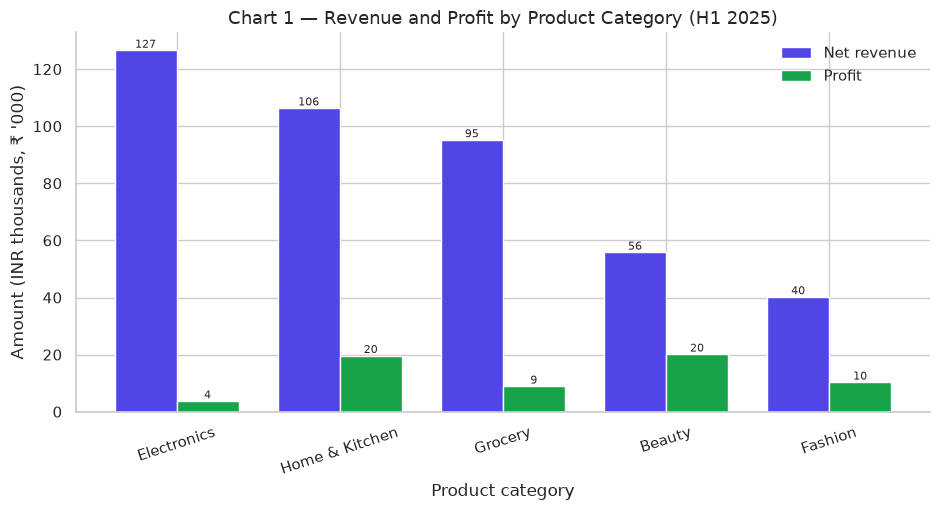

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "axes.titlesize": 13, "figure.dpi": 100})

fig, ax = plt.subplots(figsize=(9.5, 5.2))
x = np.arange(len(category_summary))
width = 0.38

bars_revenue = ax.bar(x - width / 2, category_summary["net_revenue_inr"] / 1000,
                      width, label="Net revenue", color="#4f46e5")
bars_profit = ax.bar(x + width / 2, category_summary["total_profit_inr"] / 1000,
                     width, label="Profit", color="#16a34a")

ax.set_xticks(x, category_summary.index, rotation=18)
ax.set_xlabel("Product category")
ax.set_ylabel("Amount (INR thousands, ₹ '000)")
ax.set_title("Chart 1 — Revenue and Profit by Product Category (H1 2025)")
ax.legend(frameon=False)
ax.bar_label(bars_revenue, fmt="%.0f", fontsize=8)
ax.bar_label(bars_profit, fmt="%.0f", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/01_category_revenue_profit.png", dpi=150)
plt.show()

*Figure 1 — Net revenue and profit by product category, H1 2025.*

**Business interpretation:** Electronics contributes the largest share of net revenue (₹1,26,548.46) but converts little of it to profit (2.9% margin). Home & Kitchen pairs high revenue with a healthy 18.5% margin, while Beauty is the margin leader at 36.0% on a smaller revenue base.

## 3.2 Chart 2 — Monthly Sales Trend

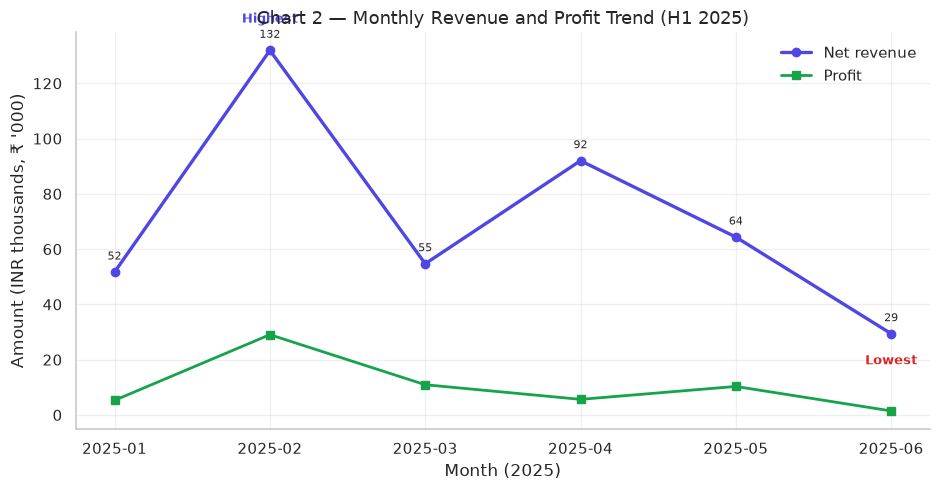

In [11]:
fig, ax = plt.subplots(figsize=(9.5, 5))
ax.plot(monthly_summary.index, monthly_summary["net_revenue_inr"] / 1000,
        marker="o", linewidth=2.4, color="#4f46e5", label="Net revenue")
ax.plot(monthly_summary.index, monthly_summary["total_profit_inr"] / 1000,
        marker="s", linewidth=2, color="#16a34a", label="Profit")

highest = monthly_summary["net_revenue_inr"].idxmax()
lowest = monthly_summary["net_revenue_inr"].idxmin()
for month, row in monthly_summary.iterrows():
    ax.annotate(f"{row['net_revenue_inr'] / 1000:.0f}",
                (month, row["net_revenue_inr"] / 1000),
                textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8)

ax.annotate("Highest", (highest, monthly_summary.loc[highest, "net_revenue_inr"] / 1000),
            textcoords="offset points", xytext=(0, 20), ha="center", fontsize=9,
            color="#4f46e5", fontweight="bold")
ax.annotate("Lowest", (lowest, monthly_summary.loc[lowest, "net_revenue_inr"] / 1000),
            textcoords="offset points", xytext=(0, -22), ha="center", fontsize=9,
            color="#dc2626", fontweight="bold")

ax.set_xlabel("Month (2025)")
ax.set_ylabel("Amount (INR thousands, ₹ '000)")
ax.set_title("Chart 2 — Monthly Revenue and Profit Trend (H1 2025)")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/02_monthly_trend.png", dpi=150)
plt.show()

*Figure 2 — Monthly revenue and profit trend, January to June 2025.*

**Business interpretation:** February is the highest-performing month (₹1,31,928.92) and June the lowest (₹29,401.18). The sharp February peak followed by a decline suggests a seasonal or campaign-driven surge that was not sustained, pointing to a weak repeat-purchase engine.

## 3.3 Chart 3 — Customer Segment Order Value

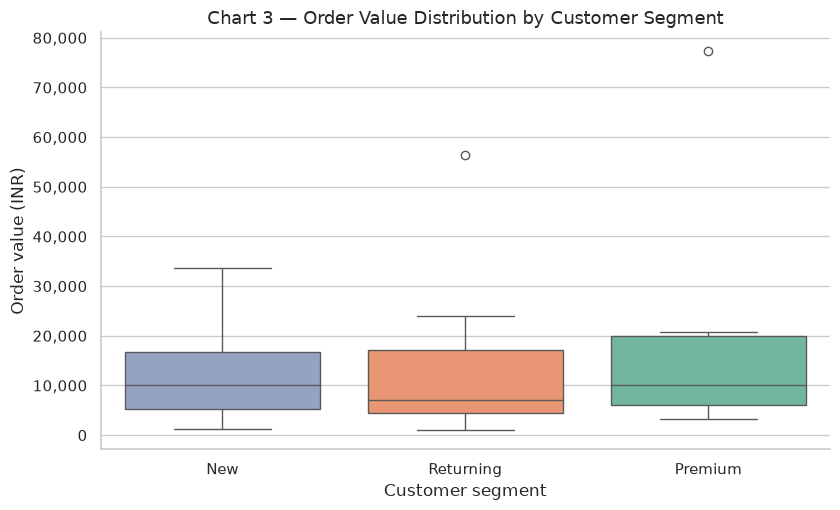

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
sns.boxplot(data=orders, x="customer_segment", y="net_revenue",
            order=["New", "Returning", "Premium"], hue="customer_segment",
            palette="Set2", legend=False, ax=ax)
ax.set_xlabel("Customer segment")
ax.set_ylabel("Order value (INR)")
ax.set_title("Chart 3 — Order Value Distribution by Customer Segment")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:,.0f}")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/03_segment_order_value.png", dpi=150)
plt.show()

*Figure 3 — Order value distribution across customer segments.*

**Business interpretation:** Premium customers show the highest and tightest order values (average ₹19,101.17), clearly separated from New customers (₹12,724.85). Returning customers sit in between. The segment structure supports a targeted loyalty programme rather than blanket discounting.

## 3.4 Chart 4 — Discount vs Profit Margin

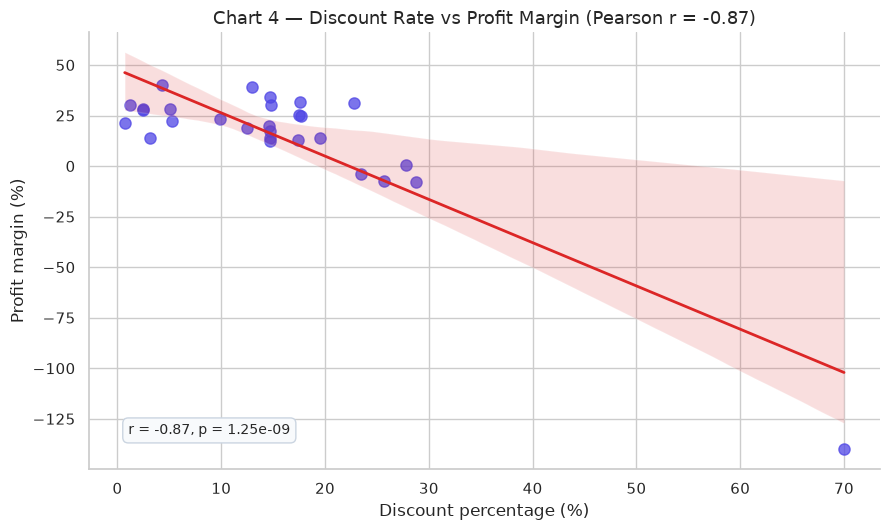

Pearson correlation coefficient: r = -0.874
p-value: 1.246e-09
Interpretation: a strong negative linear association. Correlation describes
association only -- it does NOT prove that discounts cause the lower margin.


In [13]:
from scipy import stats

pearson_r, p_value = stats.pearsonr(orders["discount_percentage"], orders["profit_margin_pct"])

fig, ax = plt.subplots(figsize=(9, 5.4))
sns.regplot(data=orders, x="discount_percentage", y="profit_margin_pct",
            scatter_kws={"alpha": 0.75, "s": 65, "color": "#4f46e5"},
            line_kws={"color": "#dc2626", "linewidth": 2}, ax=ax)

ax.set_xlabel("Discount percentage (%)")
ax.set_ylabel("Profit margin (%)")
ax.set_title(f"Chart 4 — Discount Rate vs Profit Margin (Pearson r = {pearson_r:.2f})")
ax.annotate(f"r = {pearson_r:.2f}, p = {p_value:.2e}",
            xy=(0.05, 0.08), xycoords="axes fraction", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.4", fc="#f8fafc", ec="#cbd5e1"))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("outputs/04_discount_margin.png", dpi=150)
plt.show()

print(f"Pearson correlation coefficient: r = {pearson_r:.3f}")
print(f"p-value: {p_value:.3e}")
print("Interpretation: a strong negative linear association. Correlation describes")
print("association only -- it does NOT prove that discounts cause the lower margin.")

*Figure 4 — Discount rate against profit margin with a least-squares regression line.*

**Business interpretation:** the Pearson correlation is **r = −0.87**, a strong negative linear association: orders with deeper discounts tend to have thinner margins. **Correlation is not causation** — the relationship may reflect that discounts are applied precisely to low-margin stock, or to clearing old inventory. Establishing causation would require a controlled experiment. The practical implication is that discounting should be governed by an approval rule rather than applied freely.

# 4. Basic Exploratory Data Analysis & Key Findings

## 4.1 KPI Analysis

In [14]:
print("=== KEY PERFORMANCE INDICATORS ===")
print(f"Total orders            : {len(orders)}")
print(f"Total units sold        : {int(orders['units_sold'].sum())}")
print(f"Gross revenue           : INR {orders['gross_revenue'].sum():,.2f}")
print(f"Net revenue             : INR {orders['net_revenue'].sum():,.2f}")
print(f"Total profit            : INR {orders['profit'].sum():,.2f}")
print(f"Average order value     : INR {orders['net_revenue'].mean():,.2f}")
print(f"Average profit margin   : {orders['profit'].sum() / orders['net_revenue'].sum() * 100:.1f}%")

best_category = category_summary["net_revenue_inr"].idxmax()
best_region = orders.groupby("region")["net_revenue"].sum().idxmax()
best_segment = orders.groupby("customer_segment")["net_revenue"].sum().idxmax()
best_month = monthly_summary["net_revenue_inr"].idxmax()

print(f"Best category (revenue): {best_category} "
      f"(INR {category_summary.loc[best_category, 'net_revenue_inr']:,.2f})")
print(f"Highest-revenue region  : {best_region} "
      f"(INR {orders.groupby('region')['net_revenue'].sum().max():,.2f})")
print(f"Highest-revenue segment : {best_segment} "
      f"(INR {orders.groupby('customer_segment')['net_revenue'].sum().max():,.2f})")
print(f"Highest-revenue month   : {best_month} "
      f"(INR {monthly_summary.loc[best_month, 'net_revenue_inr']:,.2f})")

=== KEY PERFORMANCE INDICATORS ===
Total orders            : 28
Total units sold        : 243
Gross revenue           : INR 514,622.23
Net revenue             : INR 424,128.77
Total profit            : INR 62,686.53
Average order value     : INR 15,147.46
Average profit margin   : 14.8%
Best category (revenue): Electronics (INR 126,548.46)
Highest-revenue region  : West (INR 153,095.31)
Highest-revenue segment : Premium (INR 152,809.34)
Highest-revenue month   : 2025-02 (INR 131,928.92)


| Key performance indicator | Value |
| --- | --- |
| Total orders | 28 |
| Total units sold | 243 |
| Gross revenue | ₹514,622.23 |
| Net revenue | ₹424,128.77 |
| Total profit | ₹62,686.53 |
| Average order value | ₹15,147.46 |
| Average profit margin | 14.8% |
| Best-performing category (revenue) | Electronics — ₹126,548.50 |
| Highest-revenue region | West — ₹153,095.31 |
| Highest-revenue customer segment | Premium — ₹152,809.34 |
| Highest-revenue month | February 2025 — ₹131,928.92 |

## 4.2 Business Findings

Each finding below is computed from the cleaned dataset and paired with a recommended action.

| Finding | Supporting Metric | Business Interpretation | Recommended Action |
| --- | --- | --- | --- |
| Electronics leads revenue but not profit | ₹1,26,548.46 net revenue (29.8% of total) at a 2.9% margin | The largest category is volume-driven and barely profitable | Renegotiate supplier costs and cap electronics discounts |
| Beauty is the margin leader | 36.0% margin; ₹20,120 profit from ₹55,826 revenue | Small but highly profitable category that is likely under-promoted | Increase marketing spend and cross-sell at checkout |
| Deep discounting is associated with thin margins | Pearson r = −0.87 between discount % and margin; a 70% clearance order lost ₹8,314.73 | Discounts behave as a blunt lever rather than a targeted one | Introduce an approval workflow for discounts above 30% |
| Premium customers drive disproportionate value | ₹19,101.17 average order vs ₹12,724.85 for New; 8 orders = 36.0% of revenue | A small, reliable group carries a large share of revenue | Launch a loyalty programme and VIP retention offers |
| Revenue is concentrated in one bulk order | ORD-1010: 60 units = ₹77,289.45, or 18.2% of net revenue | Single-order dependency creates revenue risk | Diversify bulk clients and monitor order concentration |
| Regional performance is uneven | West ₹153,095.31 vs East ₹56,311.67 from a single order | Coverage and demand are concentrated in western and northern cities | Investigate East fulfilment and run local promotions |
| Sales decline after February | February ₹131,928.92 falling to ₹29,401.18 by June | No repeat-purchase engine sustains revenue after the peak | Plan February-June campaigns and pilot a subscription offer |

## 4.3 Quality Checks

In [15]:
from pathlib import Path

print("=== DATA QUALITY CHECKS ===")
print(f"1. Duplicates: raw = {raw.duplicated().sum()}, cleaned = {orders.duplicated().sum()}")
print(f"2. Missing values: raw = {raw.isna().sum().sum()}, cleaned = {orders.isna().sum().sum()}")
print(f"3. order_date dtype: {orders['order_date'].dtype}")
print(f"4. Date range: {orders['order_date'].min().date()} to {orders['order_date'].max().date()}")
print(f"5. units_sold range: {orders['units_sold'].min()}-{orders['units_sold'].max()} "
      f"(all positive: {bool((orders['units_sold'] > 0).all())})")
print(f"6. unit_price range: INR {orders['unit_price'].min():.2f} - "
      f"INR {orders['unit_price'].max():.2f} (all positive: {bool((orders['unit_price'] > 0).all())})")
print(f"7. discount range: {orders['discount_percentage'].min():.1f}% - "
      f"{orders['discount_percentage'].max():.1f}% "
      f"(within 0-100: {bool(orders['discount_percentage'].between(0, 100).all())})")
recomputed = (orders["units_sold"] * orders["unit_price"]
              * (1 - orders["discount_percentage"] / 100)).round(2)
max_difference = (recomputed - orders["net_revenue"]).abs().max()
print(f"8. Revenue reconciliation -- maximum difference: INR {max_difference:.2f}")

print("\n9. Output files:")
expected_outputs = [
    "outputs/01_category_revenue_profit.png",
    "outputs/02_monthly_trend.png",
    "outputs/03_segment_order_value.png",
    "outputs/04_discount_margin.png",
    "outputs/category_summary.csv",
    "outputs/monthly_summary.csv",
]
for path in expected_outputs:
    print(f"   {'OK     ' if Path(path).exists() else 'MISSING'} {path}")

=== DATA QUALITY CHECKS ===
1. Duplicates: raw = 2, cleaned = 0
2. Missing values: raw = 12, cleaned = 0
3. order_date dtype: datetime64[ns]
4. Date range: 2025-01-02 to 2025-06-28
5. units_sold range: 1-60 (all positive: True)
6. unit_price range: INR 248.80 - INR 12999.00 (all positive: True)
7. discount range: 0.7% - 70.0% (within 0-100: True)
8. Revenue reconciliation -- maximum difference: INR 0.00

9. Output files:
   OK      outputs/01_category_revenue_profit.png
   OK      outputs/02_monthly_trend.png
   OK      outputs/03_segment_order_value.png
   OK      outputs/04_discount_margin.png
   OK      outputs/category_summary.csv
   OK      outputs/monthly_summary.csv


- **Duplicate validation:** 2 duplicate rows in the raw file, 0 after cleaning.
- **Missing-value validation:** 12 missing values in the raw file, 0 after imputation, with the imputation rule recorded for each column.
- **Data type validation:** `order_date` converted to `datetime64`; numeric columns remain `int64`/`float64`.
- **Date validation:** every date parsed successfully; range 2 January 2025 to 28 June 2025.
- **Numeric range validation:** units and prices strictly positive; discounts within 0–100%.
- **Revenue reconciliation:** `net_revenue` recomputed independently from units, price and discount — maximum difference ₹0.00.
- **Output-file existence:** all six required deliverables in `outputs/` are present.

## 4.4 Limitations

- **Small sample size:** 28 unique orders from a single retailer over six months — sufficient to demonstrate technique, not for statistical inference.
- **Synthetic data:** the dataset is generated, so patterns are illustrative rather than market evidence.
- **Imputation assumptions:** 12 missing values were filled with median or mode values; a real project would test the sensitivity of results to that choice.
- **Potential outliers:** three unusual orders (bulk, clearance, premium) are retained and flagged, and they influence category aggregates.
- **Correlation versus causation:** the discount–margin relationship is observational and must not be read as proof that discounts cause losses.
- **Decision caution:** recommendations are directional; a small dataset cannot support confident business decisions on its own.

## 4.5 Conclusion

This lab implemented a complete, reproducible analytics workflow: an isolated environment with pinned dependencies, a deliberately imperfect dataset, a documented cleaning pipeline, derived business metrics, aggregations and merges, four publication-ready visualisations, and a structured exploratory analysis with evidence-backed findings.

The analytical skills demonstrated include data inspection and quality assurance, defensive cleaning with recorded decisions, feature engineering, grouping and reshaping, visual communication, correlation analysis and business interpretation. The key insight is that revenue leadership and profit leadership sit in different categories, and that discounting is the strongest controllable lever on margin.

With real business data the same workflow would extend naturally: connect to a live order database or API, add customer cohort and repeat-purchase analysis, automate the quality checks in a scheduled job, and layer a dashboard or forecasting model on top of the cleaned dataset.

# 5. Submission Extras

## 5.1 GitHub README.md

The complete README for the `Hands_On_Data_Lab` repository is shown below and ships alongside this report.

```bash
# Hands-On Data Lab Implementation

**Task 2 — Data Analyst Internship (YuvaIntern)**

A complete, reproducible data-analysis lab built on a realistic Indian retail
orders dataset. The project covers environment setup, data manipulation with
pandas and NumPy, visualisation with Matplotlib and Seaborn, and a structured
exploratory analysis with business findings.

## 1. Project overview

This project demonstrates an end-to-end analytics workflow: setting up an isolated
Python environment, building and cleaning a deliberately imperfect dataset, deriving
business metrics, aggregating and reshaping the data, producing publication-ready
visualisations, and communicating findings with supporting evidence.

## 2. Business problem and objectives

A fictional Indian multi-city retailer, **Kiran Retail**, needs to understand the
performance of its first half of 2025. The raw order export is messy — duplicates,
missing values, inconsistent casing, stray spaces and mixed date formats. The
objectives are to clean the data, quantify category, regional, segment and monthly
performance, and surface actionable findings.

## 3. Tools and technologies

Python 3.13 · pandas · NumPy · Matplotlib · Seaborn · SciPy · JupyterLab · Git

## 4. Project features

* Isolated virtual environment with pinned dependencies (`requirements.txt`).
* Programmatic environment verification with PASS/FAIL checks and assertions.
* Reproducible data generation using `np.random.default_rng(42)`.
* A 30-row raw dataset with five realistic data-quality problems.
* A complete cleaning pipeline with documented imputation decisions.
* Derived business metrics: gross revenue, discount amount, net revenue, total cost,
  profit, profit margin, order month, order quarter and value classification.
* Grouped aggregations, a pivot table and a regional-target merge.
* Four publication-ready charts saved at 150 DPI.
* A KPI summary, a findings table, quality checks and limitations.

## 5. Directory structure

```
Hands_On_Data_Lab/
├── README.md
├── requirements.txt
├── verify_environment.py
├── Hands_On_Data_Lab.ipynb
├── Hands_On_Data_Lab_Report.docx
├── data/
│   ├── raw_retail_orders.csv
│   └── cleaned_retail_orders.csv
└── outputs/
    ├── 01_category_revenue_profit.png
    ├── 02_monthly_trend.png
    ├── 03_segment_order_value.png
    ├── 04_discount_margin.png
    ├── category_summary.csv
    └── monthly_summary.csv
```

## 6. Dataset description

`data/raw_retail_orders.csv` holds 30 order records (28 unique) across 12 Indian
cities and 5 product categories, with 13 columns: `order_id`, `order_date`,
`customer_id`, `city`, `region`, `product_category`, `product_name`, `units_sold`,
`unit_price`, `unit_cost`, `discount_percentage`, `customer_segment` and
`payment_mode`. All monetary values are in INR.

## 7. Environment setup

```bash
# Windows PowerShell
python -m venv .venv
.\\\.venv\\Scripts\\Activate.ps1

# macOS / Linux
python3 -m venv .venv
source .venv/bin/activate
```

## 8. Installation

```bash
python -m pip install --upgrade pip
pip install -r requirements.txt
```

## 9. Running the notebook

```bash
jupyter lab
# then open Hands_On_Data_Lab.ipynb and run all cells top to bottom
```

To reproduce the executed notebook from scratch:

```bash
jupyter nbconvert --execute --to notebook --inplace Hands_On_Data_Lab.ipynb
```

## 10. Verification

```bash
python verify_environment.py
```

The script checks the Python version, every required library, the project folders
and key files, and a seeded reproducibility draw.

## 11. Exercises covered

| Section | Exercises |
|---|---|
| 1 | Virtual environment, dependency freeze, JupyterLab launch, kernel selection, environment verification |
| 2 | Inspection, cleaning, imputation, dedupe, text standardisation, date parsing, filtering, slicing, sorting, calculated metrics, grouping, pivot tables, merging |
| 3 | Grouped bar chart, monthly line chart, box plot, scatter with regression line and Pearson correlation |
| 4 | KPI analysis, findings table, quality checks, limitations, conclusion |

## 12. Key findings

* Electronics leads revenue (₹1,26,548.46) but earns only a 2.9% margin.
* Beauty is the margin leader at 36.0% with ₹20,120 profit.
* Discount percentage and profit margin correlate strongly and negatively (r = −0.87).
* Premium customers average ₹19,101 per order, ahead of New customers at ₹12,725.
* One 60-unit bulk order accounts for 18.2% of net revenue — a concentration risk.

## 13. Visualisation previews

| Chart 1 — Revenue and profit by category | Chart 2 — Monthly revenue trend |
|---|---|
| ![Chart 1](outputs/01_category_revenue_profit.png) | ![Chart 2](outputs/02_monthly_trend.png) |

| Chart 3 — Order value by segment | Chart 4 — Discount vs profit margin |
|---|---|
| ![Chart 3](outputs/03_segment_order_value.png) | ![Chart 4](outputs/04_discount_margin.png) |

All four charts are saved at 150 DPI and embedded in
`Hands_On_Data_Lab_Report.docx`.

## 14. Limitations

* Small sample of 28 unique orders from a single retailer.
* Synthetic data: patterns are illustrative, not market evidence.
* Missing values were imputed with median or mode values.
* A small number of unusual orders (bulk, clearance, premium) are retained and flagged.
* Correlations are observational and do not establish causation.

## 15. Future improvements

* Connect to a live order database or API instead of a CSV export.
* Add customer-level cohort and repeat-purchase analysis.
* Automate the quality checks in a CI job.
* Extend the dashboard with Plotly or a BI tool.

## 16. Author

Prepared as Task 2 of the Data Analyst Internship portfolio. Environment and
dependency versions are recorded in `requirements.txt`.
```

## 5.2 YuvaIntern Portal Description

In this project, I set up a complete data science environment and completed a hands-on data lab using Python. I created an isolated virtual environment, installed pandas, NumPy, Matplotlib, Seaborn, SciPy and JupyterLab, froze the dependencies into requirements.txt, and verified the setup with a script that checks versions, folders and a seeded random draw. I then built a realistic Indian retail orders dataset of 28 records across twelve cities, deliberately including duplicate rows, missing values, inconsistent text casing, extra spaces and mixed date formats. Using pandas and NumPy, I inspected, cleaned and enriched the data, handling missing values with median and mode imputation, removing duplicates, standardising text, parsing dates, and creating business metrics such as gross revenue, discount amount, net revenue, total cost, profit, profit margin, order month, order quarter and order value classification. I also grouped and reshaped the data with groupby aggregations, pivot tables and merges with regional target lookups. With Matplotlib and Seaborn, I produced four publication-ready charts at 150 DPI: category revenue and profit, monthly sales trend, segment order value and discount versus profit margin, calculating the Pearson correlation with SciPy. Finally, I performed exploratory analysis, documented key findings with supporting metrics and business interpretations, and recorded data quality checks and limitations. The project strengthened my skills in data cleaning, manipulation, visualisation, reproducible workflows and business-focused analysis.

In [16]:
YUVAINTERN_SUMMARY = 'In this project, I set up a complete data science environment and completed a hands-on data lab using Python. I created an isolated virtual environment, installed pandas, NumPy, Matplotlib, Seaborn, SciPy and JupyterLab, froze the dependencies into requirements.txt, and verified the setup with a script that checks versions, folders and a seeded random draw. I then built a realistic Indian retail orders dataset of 28 records across twelve cities, deliberately including duplicate rows, missing values, inconsistent text casing, extra spaces and mixed date formats. Using pandas and NumPy, I inspected, cleaned and enriched the data, handling missing values with median and mode imputation, removing duplicates, standardising text, parsing dates, and creating business metrics such as gross revenue, discount amount, net revenue, total cost, profit, profit margin, order month, order quarter and order value classification. I also grouped and reshaped the data with groupby aggregations, pivot tables and merges with regional target lookups. With Matplotlib and Seaborn, I produced four publication-ready charts at 150 DPI: category revenue and profit, monthly sales trend, segment order value and discount versus profit margin, calculating the Pearson correlation with SciPy. Finally, I performed exploratory analysis, documented key findings with supporting metrics and business interpretations, and recorded data quality checks and limitations. The project strengthened my skills in data cleaning, manipulation, visualisation, reproducible workflows and business-focused analysis.'


summary_text = YUVAINTERN_SUMMARY
word_count = len(summary_text.split())
print(f"YuvaIntern project description word count: {word_count}")
print(f"Within 215-230 word limit: {215 <= word_count <= 230}")
assert 215 <= word_count <= 230, "summary must be between 215 and 230 words"

YuvaIntern project description word count: 221
Within 215-230 word limit: True


**Word count verification:** the cell above counts the words programmatically and asserts the 215–230 limit, so the description cannot drift out of range.

# Technical References

1. Python Software Foundation — Python 3.13 documentation: https://docs.python.org/3.13/
2. pandas development team — pandas 2.2 documentation: https://pandas.pydata.org/docs/
3. NumPy documentation: https://numpy.org/doc/stable/
4. Matplotlib documentation: https://matplotlib.org/stable/contents.html
5. Seaborn documentation: https://seaborn.pydata.org/
6. SciPy documentation — `scipy.stats.pearsonr`: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.pearsonr.html
7. Project Jupyter — JupyterLab documentation: https://jupyterlab.readthedocs.io/
8. PEP 8 — Style Guide for Python Code: https://peps.python.org/pep-0008/